In [54]:
import os
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True), override=True)

os.environ["GROQ_API_KEY"]   = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"]       = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY") or os.getenv("tavily_api", "")
os.environ.setdefault("USER_AGENT", "rag-learning-notebook/1.0")

assert os.environ["GROQ_API_KEY"], "groq_api missing in .env"
assert os.environ["TAVILY_API_KEY"], "tavily_api missing in .env"

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

# Groq free tier: about 8,000 tokens per minute for gpt-oss-20b.
# Groq counts max_tokens against that limit too, so keep it small.
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    max_tokens=1500,
    max_retries=5,     # retry automatically on 429 (per-minute limit reached)
)

# The blog writer needs a longer output; its prompt is small, so prompt + output still fits
writer_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0.3,
    max_tokens=3500,
    reasoning_effort="low",   # spend tokens on the blog, not on hidden reasoning
    max_retries=5,
)

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
llm

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001D5EC916250>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001D5EC915350>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'), max_retries=5, max_tokens=1500)

In [55]:
from langchain_tavily import TavilySearch
from langchain_core.tools import Tool, tool
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain.agents.middleware import ToolCallLimitMiddleware

_tavily = TavilySearch(max_results=3)

@tool
def web_search(query: str) -> str:
    """Search the web for up-to-date information. Returns short snippets with URLs."""
    print("🌐 Using tool: web_search")
    res = _tavily.invoke({"query": query})
    return "\n\n".join(
        f"[{r['title']}]({r['url']})\n{r['content'][:600]}"   # each result capped at 600 characters
        for r in res.get("results", [])
    )

tavily_tool = web_search   # alias used by the later cells


def make_retriever_tool_from_text(file, name, desc):
    docs = TextLoader(file, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, embeddings)          # HF embeddings instead of OpenAI
    retriever = vs.as_retriever(search_kwargs={"k": 3})

    def tool_func(query: str) -> str:
        print(f"📚 Using tool: {name}")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc, func=tool_func)


def tool_limit(n: int = 3):
    """Every tool result is added to the agent's history, so cap tool calls per run
    to keep each request under Groq's 8,000 tokens-per-minute limit."""
    return [ToolCallLimitMiddleware(run_limit=n)]


internal_tool_1 = make_retriever_tool_from_text(
    "internal_docs.txt",
    "InternalResearchNotes",
    "Search internal engineering notes about transformer variants used in production",
)
print(internal_tool_1.invoke("Which transformer variants are in production?")[:500])

📚 Using tool: InternalResearchNotes
---------------------------------------------------------------------
SECTION 1: EXECUTIVE SUMMARY
---------------------------------------------------------------------

This report summarizes every transformer-based model that is currently running
in production, in limited rollout, or under evaluation across NovaMind Labs
products. It covers why each model was chosen, how it is deployed, how it
performs, what it costs, which incidents it caused, and what we plan to do next.

Internal Engineerin


In [56]:
from typing import Literal
from langchain_core.messages import BaseMessage, HumanMessage
from langchain.agents import create_agent          # langchain 1.x replacement of create_react_agent
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.types import Command

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        return END
    return goto

def make_system_prompt(suffix: str) -> str:
    return (
        "You are a helpful AI assistant, collaborating with other assistants."
        " Use the provided tools to progress towards answering the question."
        " If you are unable to fully answer, that's OK, another assistant with different tools"
        " will help where you left off. Execute what you can to make progress."
        " If you or any of the other assistants have the final answer or deliverable,"
        " prefix your response with FINAL ANSWER so the team knows to stop."
        f"\n{suffix}"
    )

def compact(state: MessagesState) -> dict:
    """Give the agent only the user's question and the latest message, not the whole history,
    so the request size stays the same no matter how many rounds the agents take."""
    msgs = state["messages"]
    return {"messages": msgs[:1] + msgs[-1:] if len(msgs) > 1 else msgs}

In [57]:
research_agent = create_agent(
    llm,
    tools=[internal_tool_1, tavily_tool],
    middleware=tool_limit(3),
    system_prompt=make_system_prompt(
        "You can only do research. Use both the internal notes tool and web search."
        " Make at most 3 tool calls, then return concise research notes (bullet points, under 300 words)."
        " Do NOT write the blog yourself and do NOT say FINAL ANSWER: your content writer colleague does that."
    ),
)

def research_node(state: MessagesState) -> Command[Literal["blog_generator", END]]:
    result = research_agent.invoke(compact(state))
    last = result["messages"][-1]
    goto = get_next_node(last, "blog_generator")
    # Add only the final notes to the shared state, not the raw tool outputs (keeps tokens low)
    return Command(
        update={"messages": [HumanMessage(content=last.content, name="researcher")]},
        goto=goto,
    )

In [58]:
blog_agent = create_agent(
    writer_llm,
    tools=[],
    system_prompt=make_system_prompt(
        "You can only write a detailed blog (about 1,000 words) from the researcher's notes."
        " When the blog is complete, start your reply with FINAL ANSWER."
        " You are working with a researcher colleague."
    ),
)

def blog_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = blog_agent.invoke(compact(state))
    last = result["messages"][-1]
    goto = get_next_node(last, "researcher")
    # The LLM sometimes forgets "FINAL ANSWER". A full-length blog means the job is done,
    # so stop anyway instead of sending it back to the researcher for another round.
    if len(last.content) > 3000:
        goto = END
    return Command(
        update={"messages": [HumanMessage(content=last.content, name="blog_generator")]},
        goto=goto,
    )

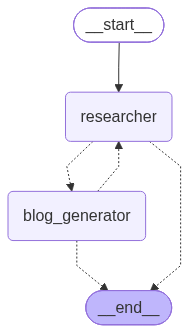

In [59]:
workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator", blog_node)
workflow.add_edge(START, "researcher")
graph = workflow.compile()
graph

In [60]:
# recursion_limit = safety net in case agents keep passing the task back and forth
response = graph.invoke(
    {"messages": [("user", "Write a detailed blog on transformer variants in production deployments. "
                           "Keep research notes short.")]},
    config={"recursion_limit": 12},
)
print(response["messages"][-1].content.replace("FINAL ANSWER", "").lstrip("*# "))

📚 Using tool: InternalResearchNotes
🌐 Using tool: web_search


# Transformer Variants in Production Deployments  
*How companies are turning research‑grade models into real‑world services*

---

## 1. Why the “variant” craze matters

The original transformer papers (Vaswani et al., 2017) introduced a powerful sequence‑to‑sequence architecture that has since become the backbone of NLP, computer vision, and multimodal systems. Yet the raw transformer is heavy: millions of parameters, large memory footprints, and high inference latency. In production, where latency, cost, and device constraints matter, engineers have engineered a family of *variants* that trade off a bit of accuracy for orders‑of‑magnitude gains in speed, memory, or energy efficiency.

Below is a snapshot of how these variants are being deployed today, distilled from internal engineering reports (NovaMind Labs, 2025) and public deployment patterns. The goal is to give you a practical sense of what works, where, and why.



In [61]:
research_agent = create_agent(
    model=llm,
    tools=[web_search, internal_tool_1],
    middleware=tool_limit(3),
    system_prompt=(
        "You are a research agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with research-related tasks, DO NOT do any math\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name="research_agent",
)

def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b

def divide(a: float, b: float) -> float:
    """Divide two numbers."""
    return a / b

math_agent = create_agent(
    model=llm,
    tools=[add, multiply, divide],
    system_prompt=(
        "You are a math agent.\n\n"
        "INSTRUCTIONS:\n"
        "- Assist ONLY with math-related tasks\n"
        "- After you're done with your tasks, respond to the supervisor directly\n"
        "- Respond ONLY with the results of your work, do NOT include ANY other text."
    ),
    name="math_agent",
)